In [68]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [14]:
import sys
sys.path.append("../src")

In [2]:
DATA_DIR = "../data/troupe/TLSC"

In [3]:
import pickle

with open(f"{DATA_DIR}/processed_data/trees.pkl", "rb") as f:
    data = pickle.load(f)

# print(type(data))
print('Number of trees: ', len(data))

Number of trees:  11


In [4]:
t_id = 0
t = data[t_id]
t.describe()
# t.convert_to_ultrametric()
# t.describe()

# t.show()
# t.write(outfile='test.nwk')

Number of leaf nodes:	272
Total number of nodes:	543
Rooted:	Yes
Most distant node:	AATGGCTGTAATGATG-1
Max. distance:	0.994189


In [5]:
import networkx as nx

def ete_to_nx(t):
    G = nx.DiGraph()

    node_ids = {}
    
    for i, node in enumerate(t.traverse("preorder")):
        node_ids[node] = i + 1
    
    G.add_node(0, name="root", dist=0.0, is_leaf=False)

    for node in t.traverse("preorder"):
        node_id = node_ids[node]

        attrs = {
            "name": node.name,
            "dist": node.dist,
            "is_leaf": node.is_leaf()
        }

        for attr in ["state", "state_coarse", "state_fine"]:
            if hasattr(node, attr):
                attrs[attr] = getattr(node, attr)

        G.add_node(node_id, **attrs)

        if node.up:
            G.add_edge(node_ids[node.up], node_id, length=node.dist)
        else:
            G.add_edge(0, node_id, length=node.dist)

    G.graph["root"] = 0

    return G

In [6]:
T = ete_to_nx(t)
T

In [104]:
T.nodes(data=True)

NodeDataView({0: {'name': 'root', 'dist': 0.0, 'is_leaf': False}, 1: {'name': '', 'dist': 0.005811072964601553, 'is_leaf': False}, 2: {'name': 'node_40', 'dist': 0.005811072975567898, 'is_leaf': False}, 3: {'name': 'node_78', 'dist': 0.0058110729830772225, 'is_leaf': False}, 4: {'name': 'node_100', 'dist': 0.005811072997589817, 'is_leaf': False}, 5: {'name': 'node_172', 'dist': 0.005811072961882457, 'is_leaf': False}, 6: {'name': 'node_332', 'dist': 0.005811072951924963, 'is_leaf': False}, 7: {'name': 'node_452', 'dist': 0.005811072945886988, 'is_leaf': False}, 8: {'name': 'node_458', 'dist': 0.00581107294701236, 'is_leaf': False}, 9: {'name': 'node_520', 'dist': 0.2005793007284973, 'is_leaf': False}, 10: {'name': 'node_528', 'dist': 0.23005013337846075, 'is_leaf': False}, 11: {'name': 'AAACGAAGTCCTGGTG-1', 'dist': 0.5170709091515836, 'is_leaf': True, 'state': 'Somite', 'state_coarse': 'Somite', 'state_fine': 'SomiteDermo'}, 12: {'name': 'CTCGAGGCACTGAGGA-1', 'dist': 0.5170709091515836

In [105]:
T.edges(data=True)

OutEdgeDataView([(0, 1, {'length': 0.005811072964601553}), (1, 2, {'length': 0.005811072975567898}), (1, 505, {'length': 0.07834987421325626}), (2, 3, {'length': 0.0058110729830772225}), (2, 466, {'length': 0.3537442625810779}), (3, 4, {'length': 0.005811072997589817}), (3, 443, {'length': 0.0871950463235649}), (4, 5, {'length': 0.005811072961882457}), (4, 372, {'length': 0.00581107301562022}), (5, 6, {'length': 0.005811072951924963}), (5, 205, {'length': 0.005811073011180858}), (6, 7, {'length': 0.005811072945886988}), (6, 86, {'length': 0.005811073126349352}), (7, 8, {'length': 0.00581107294701236}), (7, 81, {'length': 0.5179934031330352}), (8, 9, {'length': 0.2005793007284973}), (8, 20, {'length': 0.005811072949453414}), (9, 10, {'length': 0.23005013337846075}), (9, 13, {'length': 0.10239964351456428}), (10, 11, {'length': 0.5170709091515836}), (10, 12, {'length': 0.5170709091515836}), (13, 14, {'length': 0.3560940637939932}), (13, 17, {'length': 0.10856481752108918}), (14, 15, {'le

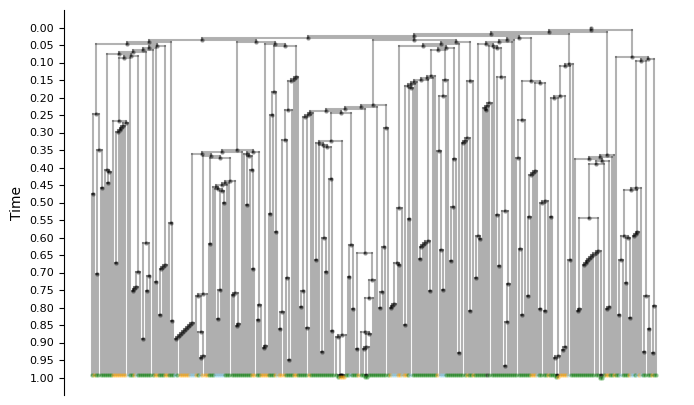

In [106]:
from plotters import draw_ultrametric_tree

draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False)

In [7]:
def get_min_max_distances(T):
    leaves = [n for n in T.nodes() if T.out_degree(n) == 0]
    distances = {}
    for leaf in leaves:
        distances[leaf] = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='length')
    min_distance = min(distances.values())
    max_distance = max(distances.values())
    return min_distance, max_distance

In [8]:
min_distance, max_distance = get_min_max_distances(T)
print(min_distance, max_distance)

0.9941889269497115 1.0


In [9]:
# EPS = 1e-4
scale = 1 / max_distance  # scale to make the min leaf at 1

In [10]:
for u, v, d in T.edges(data=True):
    d['length'] *= scale

In [111]:
get_min_max_distances(T)

(0.9941889269497115, 1.0)

In [11]:
leaves = [n for n in T.nodes() if T.out_degree(n) == 0]

for leaf in leaves:
    dist = nx.shortest_path_length(T, source=T.graph['root'], target=leaf, weight='length')
    
    if dist < 1.0:
        parent = list(T.predecessors(leaf))[0]
        edge_length = T[parent][leaf]['length']
        excess = 1.0 - dist
        T[parent][leaf]['length'] = edge_length + excess

In [113]:
get_min_max_distances(T)

(1.0, 1.0)

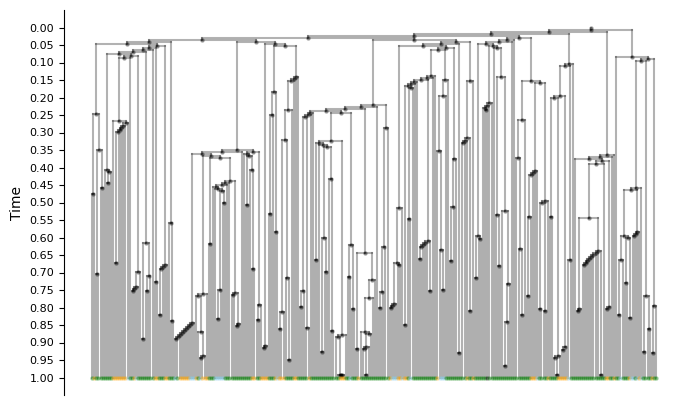

In [114]:
draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False)

In [12]:
import networkx as nx

def enforce_min_edge_length(G, root, min_length):
    """
    Adjust node times so that every edge satisfies

        T[parent] - T[child] >= min_length

    Leaves are kept fixed.
    Internal nodes are moved upward only when necessary.

    Updates:
        node['T']
        edge['length']

    Parameters
    ----------
    G : nx.DiGraph
        Rooted tree with parent -> child edges.
    root : node
        Root node.
    min_length : float
        Minimum allowed edge length.

    Returns
    -------
    nx.DiGraph
        Modified copy of G.
    """

    H = G.copy()

    # Postorder = children before parent
    for u in nx.dfs_postorder_nodes(H, root):

        children = list(H.successors(u))

        # leaf: fixed
        if not children:
            continue

        required_time = max(
            H.nodes[v]["T"] + min_length
            for v in children
        )

        # move parent upward only if necessary
        if H.nodes[u]["T"] < required_time:
            H.nodes[u]["T"] = required_time

    # recompute edge lengths
    for u, v in H.edges():
        H.edges[u, v]["length"] = (
            H.nodes[u]["T"] - H.nodes[v]["T"]
        )

    return H

In [15]:
from likelihood import add_node_times

T = add_node_times(T, root=T.graph['root'])

In [16]:
T = enforce_min_edge_length(T, root=T.graph['root'], min_length=0.001)

In [118]:
get_min_max_distances(T)

(1.0, 1.0)

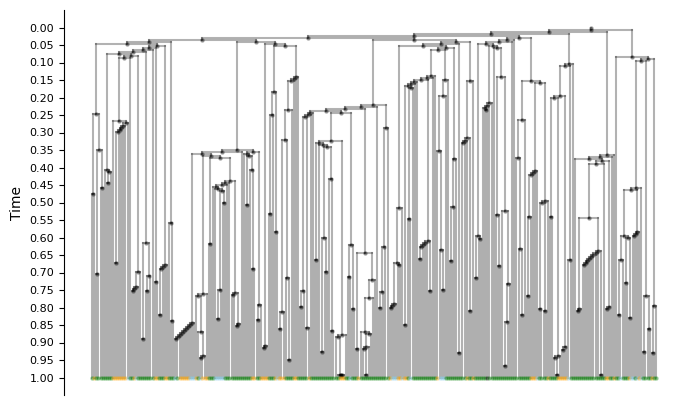

In [119]:
draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False)

In [120]:
get_min_max_distances(T)

(1.0, 1.0)

In [17]:
from likelihood import add_node_times

T = add_node_times(T, root=T.graph['root'])

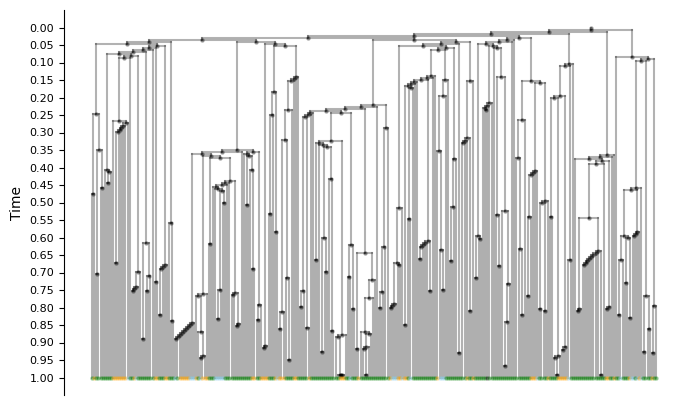

In [122]:
draw_ultrametric_tree(T, root=T.graph['root'], add_labels=False)

In [123]:
from collections import defaultdict

cell_state_counts = defaultdict(int)

for node, d in T.nodes(data=True):
    if 'state' in d:
        cell_state_counts[d.get('state')] += 1

cell_state_counts

defaultdict(int, {'Somite': 180, 'NMPs': 62, 'NeuralTube': 29, 'PCGLC': 1})

In [18]:
def extract_kept_subtrees(
    graph,
    keep_states=("Somite", "NeuralTube", "NMPs"),
    root=None,
    state_attribute="state",
):
    """Extract maximal subtrees whose leaves all have an allowed state."""
    if not nx.is_directed_acyclic_graph(graph):
        raise ValueError("Expected a directed acyclic tree")

    if root is None:
        root = graph.graph.get("root")
    if root is None:
        roots = [node for node, degree in graph.in_degree() if degree == 0]
        if len(roots) != 1:
            raise ValueError("Specify root when the graph does not have exactly one root")
        root = roots[0]
    if root not in graph:
        raise ValueError(f"Root node {root!r} is not in the graph")

    allowed_states = set(keep_states)
    subtrees = []

    def make_subtree(nodes, subtree_root):
        subtree = graph.subgraph(nodes).copy()
        subtree.graph.update(graph.graph)
        subtree.graph["root"] = subtree_root
        return subtree

    def classify(node):
        children = list(graph.successors(node))
        if not children:
            is_good_leaf = graph.nodes[node].get(state_attribute) in allowed_states
            return is_good_leaf, {node} if is_good_leaf else set(), []

        child_results = []
        nested_subtrees = []
        for child in children:
            child_is_good, child_nodes, child_subtrees = classify(child)
            child_results.append((child, child_is_good, child_nodes))
            nested_subtrees.extend(child_subtrees)

        good_children = [result for result in child_results if result[1]]
        if len(good_children) == len(children):
            kept_nodes = {node}
            for _, _, child_nodes in good_children:
                kept_nodes.update(child_nodes)
            return True, kept_nodes, nested_subtrees

        if good_children:
            kept_nodes = {node}
            for _, _, child_nodes in good_children:
                kept_nodes.update(child_nodes)
            nested_subtrees.append(make_subtree(kept_nodes, node))

        return False, set(), nested_subtrees

    whole_tree_is_good, whole_tree_nodes, nested_subtrees = classify(root)
    if whole_tree_is_good:
        return [make_subtree(whole_tree_nodes, root)]
    return nested_subtrees

In [19]:
from collections import Counter

T_target_subtrees = extract_kept_subtrees(T)
allowed_leaf_states = {"Somite", "NeuralTube", "NMPs"}
source_kept_leaves = Counter(
    node
    for node, data in T.nodes(data=True)
    if T.out_degree(node) == 0 and data.get("state") in allowed_leaf_states
)
extracted_leaves = Counter(
    node
    for subtree in T_target_subtrees
    for node, data in subtree.nodes(data=True)
    if subtree.out_degree(node) == 0
)
assert extracted_leaves == source_kept_leaves

for index, subtree in enumerate(T_target_subtrees):
    leaf_states = {
        data.get("state")
        for node, data in subtree.nodes(data=True)
        if subtree.out_degree(node) == 0
    }
    assert leaf_states <= allowed_leaf_states
    print(
        f"Subtree {index}: root={subtree.graph['root']}, "
        f"nodes={subtree.number_of_nodes()}, edges={subtree.number_of_edges()}, "
        f"leaves={sum(1 for node in subtree if subtree.out_degree(node) == 0)}, "
        f"leaf states={sorted(leaf_states)}"
    )
print(f"Extracted {len(T_target_subtrees)} subtrees")

Subtree 0: root=388, nodes=2, edges=1, leaves=1, leaf states=['Somite']
Subtree 1: root=386, nodes=2, edges=1, leaves=1, leaf states=['Somite']
Subtree 2: root=385, nodes=2, edges=1, leaves=1, leaf states=['Somite']
Subtree 3: root=384, nodes=2, edges=1, leaves=1, leaf states=['Somite']
Subtree 4: root=383, nodes=18, edges=17, leaves=9, leaf states=['Somite']
Subtree 5: root=375, nodes=8, edges=7, leaves=4, leaf states=['Somite']
Subtree 6: root=374, nodes=2, edges=1, leaves=1, leaf states=['Somite']
Subtree 7: root=373, nodes=2, edges=1, leaves=1, leaf states=['Somite']
Subtree 8: root=372, nodes=32, edges=31, leaves=16, leaf states=['NMPs', 'NeuralTube', 'Somite']
Subtree 9: root=4, nodes=368, edges=367, leaves=184, leaf states=['NMPs', 'NeuralTube', 'Somite']
Subtree 10: root=3, nodes=24, edges=23, leaves=12, leaf states=['NMPs', 'NeuralTube', 'Somite']
Subtree 11: root=2, nodes=40, edges=39, leaves=20, leaf states=['NMPs', 'Somite']
Subtree 12: root=1, nodes=40, edges=39, leaves=20

Plotting subtree 1/13 (root=388)


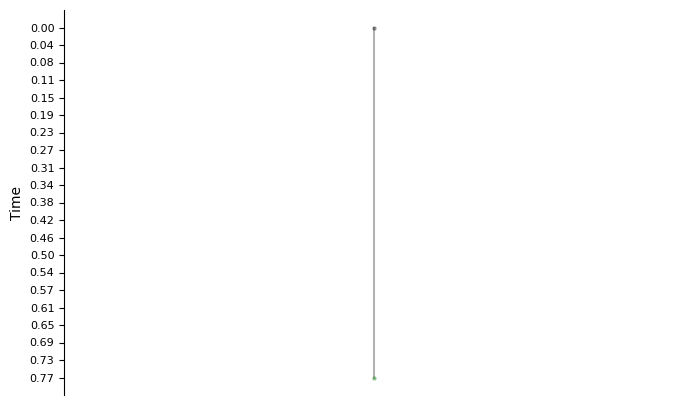

Plotting subtree 2/13 (root=386)


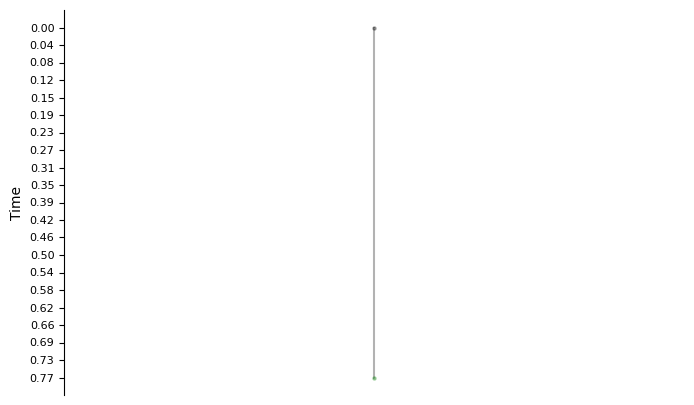

Plotting subtree 3/13 (root=385)


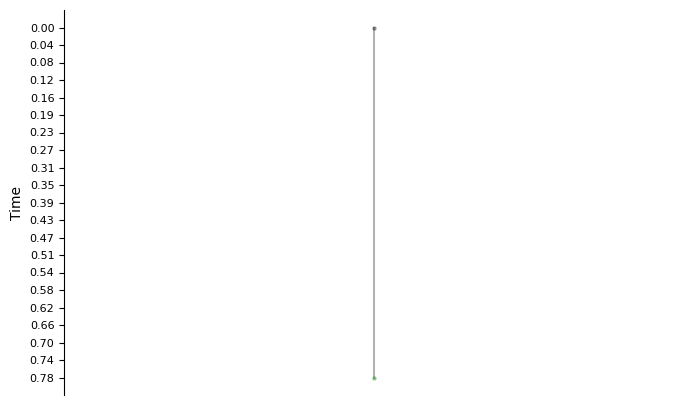

Plotting subtree 4/13 (root=384)


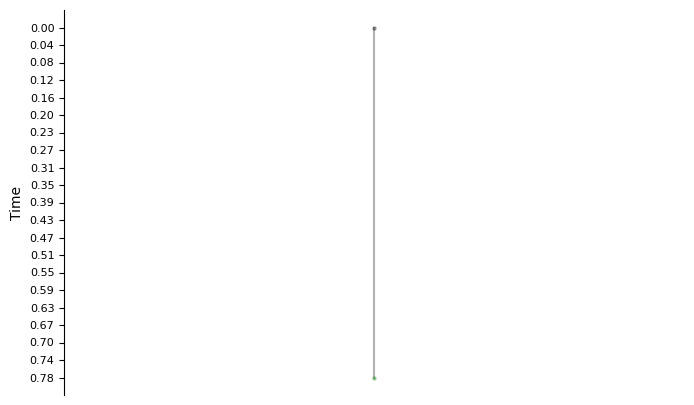

Plotting subtree 5/13 (root=383)


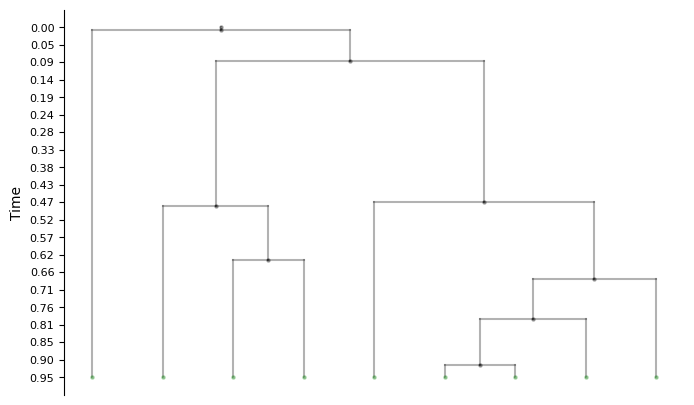

Plotting subtree 6/13 (root=375)


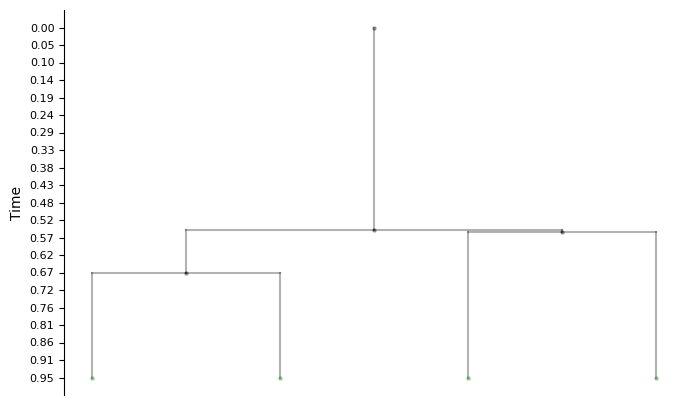

Plotting subtree 7/13 (root=374)


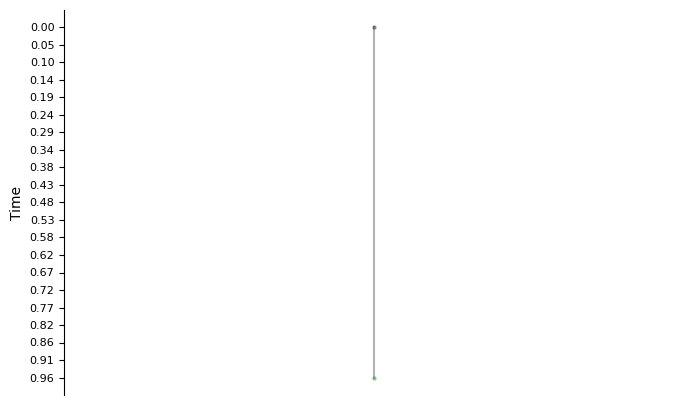

Plotting subtree 8/13 (root=373)


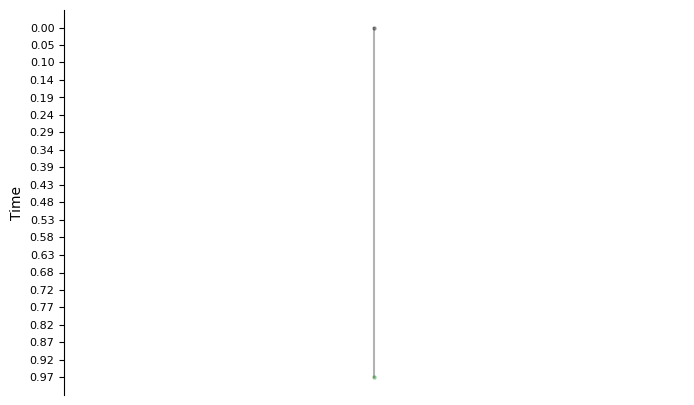

Plotting subtree 9/13 (root=372)


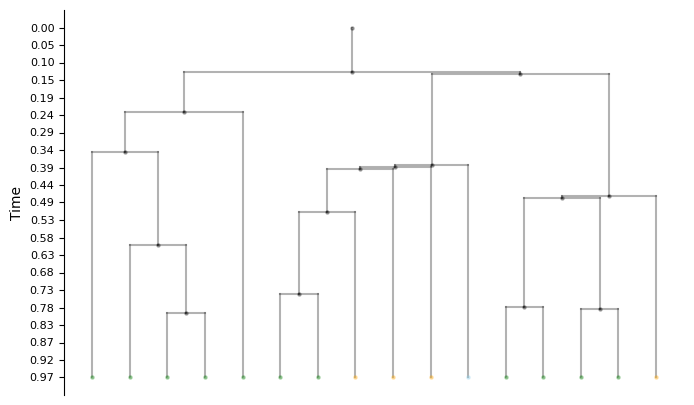

Plotting subtree 10/13 (root=4)


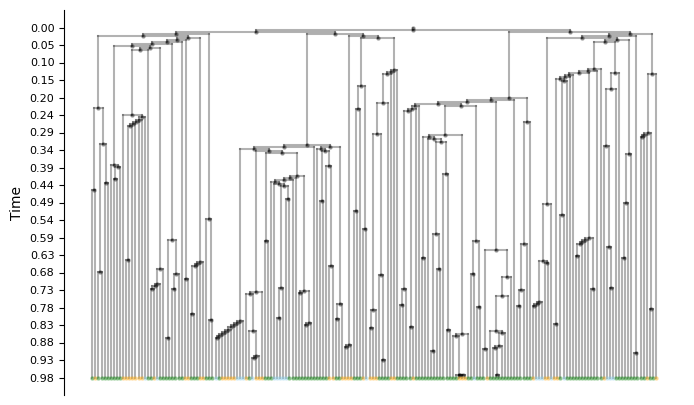

Plotting subtree 11/13 (root=3)


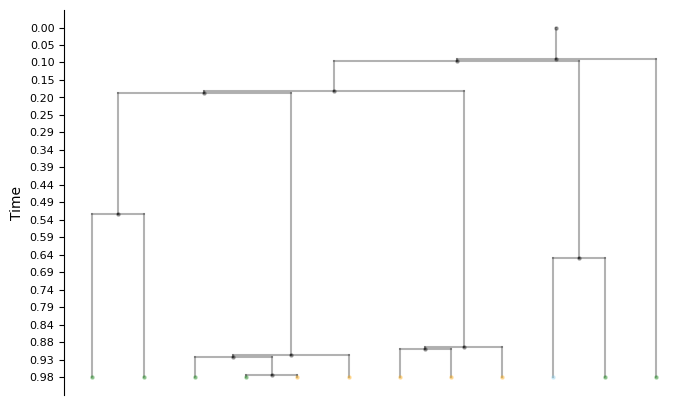

Plotting subtree 12/13 (root=2)


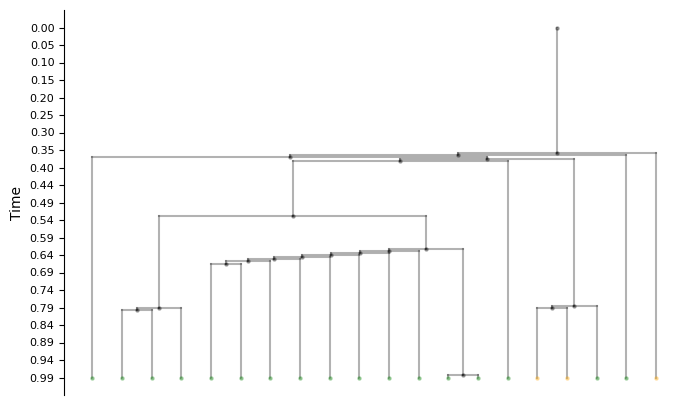

Plotting subtree 13/13 (root=1)


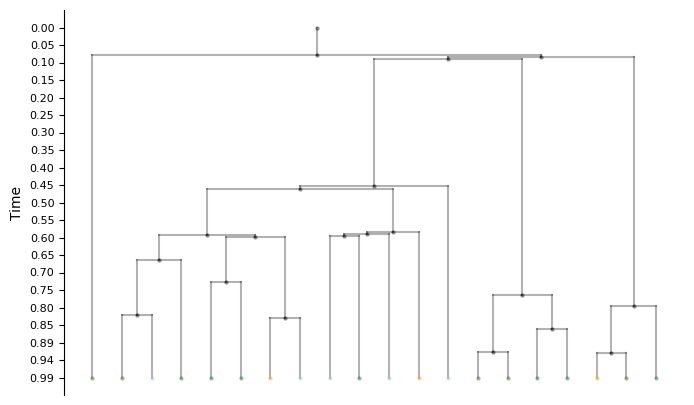

In [126]:
for index, subtree in enumerate(T_target_subtrees, start=1):
    print(f"Plotting subtree {index}/{len(T_target_subtrees)} (root={subtree.graph['root']})")
    draw_ultrametric_tree(
        subtree,
        root=subtree.graph["root"],
        add_labels=False,
    )

In [127]:
from pathlib import Path
import sys

sys.path.insert(0, str(Path(DATA_DIR).resolve().parents[2]))
from src.dataprocessor import export_tree


state_id_by_label = {
    "NMPs": 0,
    "Somite": 1,
    "NeuralTube": 2,
}


def relabel_subtree_root_first(subtree):
    subtree_root = subtree.graph["root"]
    node_order = [subtree_root] + [
        node
        for node in nx.dfs_preorder_nodes(subtree, source=subtree_root)
        if node != subtree_root
    ]
    node_mapping = {node: index for index, node in enumerate(node_order)}
    relabeled = nx.relabel_nodes(subtree, node_mapping, copy=True)
    relabeled.graph.update(subtree.graph)
    relabeled.graph["root"] = 0
    return relabeled


SUBTREE_EXPORT_DIR = Path(DATA_DIR) / "subtrees_kept_states"
SUBTREE_EXPORT_DIR.mkdir(parents=True, exist_ok=True)
T_target_subtrees_labeled = []

for index, subtree in enumerate(T_target_subtrees, start=1):
    relabeled = relabel_subtree_root_first(subtree)
    for _, data in relabeled.nodes(data=True):
        data["state"] = state_id_by_label.get(data.get("state"), -1)

    subtree_dir = SUBTREE_EXPORT_DIR / f"subtree_{index:03d}"
    subtree_dir.mkdir(parents=True, exist_ok=True)
    export_tree(
        relabeled,
        node_file=subtree_dir / "nodes.csv",
        edge_file=subtree_dir / "edges.csv",
    )
    T_target_subtrees_labeled.append(relabeled)
    assert relabeled.graph["root"] == 0
    assert set(relabeled.nodes) == set(range(relabeled.number_of_nodes()))
    print(f"Exported subtree {index} to {subtree_dir}")

Exported subtree 1 to ../data/troupe/TLSC/subtrees_kept_states/subtree_001
Exported subtree 2 to ../data/troupe/TLSC/subtrees_kept_states/subtree_002
Exported subtree 3 to ../data/troupe/TLSC/subtrees_kept_states/subtree_003
Exported subtree 4 to ../data/troupe/TLSC/subtrees_kept_states/subtree_004
Exported subtree 5 to ../data/troupe/TLSC/subtrees_kept_states/subtree_005
Exported subtree 6 to ../data/troupe/TLSC/subtrees_kept_states/subtree_006
Exported subtree 7 to ../data/troupe/TLSC/subtrees_kept_states/subtree_007
Exported subtree 8 to ../data/troupe/TLSC/subtrees_kept_states/subtree_008
Exported subtree 9 to ../data/troupe/TLSC/subtrees_kept_states/subtree_009
Exported subtree 10 to ../data/troupe/TLSC/subtrees_kept_states/subtree_010
Exported subtree 11 to ../data/troupe/TLSC/subtrees_kept_states/subtree_011
Exported subtree 12 to ../data/troupe/TLSC/subtrees_kept_states/subtree_012
Exported subtree 13 to ../data/troupe/TLSC/subtrees_kept_states/subtree_013


In [128]:
import pickle


def prepare_tree_for_subtree_export(ete_tree):
    graph = ete_to_nx(ete_tree)
    root = graph.graph["root"]
    leaves = [node for node in graph if graph.out_degree(node) == 0]

    distances = {
        leaf: nx.shortest_path_length(graph, source=root, target=leaf, weight="length")
        for leaf in leaves
    }
    max_dist = max(distances.values())
    if max_dist <= 0:
        raise ValueError("Tree has a non-positive maximum root-to-leaf distance")

    scale = 1 / max_dist
    for _, _, edge_data in graph.edges(data=True):
        edge_data["length"] *= scale

    for leaf in leaves:
        distance = nx.shortest_path_length(graph, source=root, target=leaf, weight="length")
        if distance < 1.0:
            parent = next(graph.predecessors(leaf))
            edge_length = graph[parent][leaf]["length"]
            excess = 1.0 - distance
            graph[parent][leaf]["length"] = edge_length + excess

    graph = add_node_times(graph, root=root)
    graph = enforce_min_edge_length(graph, root=root, min_length=0.01)

    distances = {
        leaf: nx.shortest_path_length(graph, source=root, target=leaf, weight="length")
        for leaf in leaves
    }
    max_dist = max(distances.values())
    if max_dist <= 0:
        raise ValueError("Tree has a non-positive maximum root-to-leaf distance")

    scale = 1 / max_dist
    for _, _, edge_data in graph.edges(data=True):
        edge_data["length"] *= scale

    for leaf in leaves:
        distance = nx.shortest_path_length(graph, source=root, target=leaf, weight="length")
        if distance < 1.0:
            parent = next(graph.predecessors(leaf))
            edge_length = graph[parent][leaf]["length"]
            excess = 1.0 - distance
            graph[parent][leaf]["length"] = edge_length + excess


    return add_node_times(graph, root=root)


def tree_key_order(item):
    key = item[0]
    try:
        return 0, int(key)
    except (TypeError, ValueError):
        return 1, str(key)


with open(Path(DATA_DIR) / "processed_data" / "trees.pkl", "rb") as tree_file:
    source_tree_data = pickle.load(tree_file)

if isinstance(source_tree_data, dict):
    source_trees = sorted(source_tree_data.items(), key=tree_key_order)
else:
    source_trees = list(enumerate(source_tree_data))

SUBTREE_EXPORT_DIR = Path(DATA_DIR) / "subtrees_kept_states"
state_id_by_label = {"NMPs": 0, "Somite": 1, "NeuralTube": 2}
exported_subtree_count = 0

for tree_number, (tree_key, ete_tree) in enumerate(source_trees, start=1):
    prepared_tree = prepare_tree_for_subtree_export(ete_tree)
    subtrees = extract_kept_subtrees(prepared_tree)
    tree_dir = SUBTREE_EXPORT_DIR / f"tree_{tree_number:03d}"
    tree_dir.mkdir(parents=True, exist_ok=True)

    for subtree_number, subtree in enumerate(subtrees, start=1):
        relabeled = relabel_subtree_root_first(subtree)
        for _, node_data in relabeled.nodes(data=True):
            node_data["state"] = state_id_by_label.get(node_data.get("state"), -1)

        subtree_dir = tree_dir / f"subtree_{subtree_number:03d}"
        subtree_dir.mkdir(parents=True, exist_ok=True)
        export_tree(
            relabeled,
            node_file=subtree_dir / "nodes.csv",
            edge_file=subtree_dir / "edges.csv",
        )
        assert relabeled.graph["root"] == 0
        assert set(relabeled.nodes) == set(range(relabeled.number_of_nodes()))
        exported_subtree_count += 1

    print(f"Tree {tree_number}/{len(source_trees)} (key={tree_key}): exported {len(subtrees)} subtrees")

print(
    f"Processed {len(source_trees)} trees and exported "
    f"{exported_subtree_count} subtrees under {SUBTREE_EXPORT_DIR}"
)

Tree 1/11 (key=0): exported 13 subtrees
Tree 2/11 (key=1): exported 5 subtrees
Tree 3/11 (key=2): exported 1 subtrees
Tree 4/11 (key=3): exported 1 subtrees
Tree 5/11 (key=4): exported 1 subtrees
Tree 6/11 (key=5): exported 14 subtrees
Tree 7/11 (key=6): exported 21 subtrees
Tree 8/11 (key=7): exported 1 subtrees
Tree 9/11 (key=8): exported 13 subtrees
Tree 10/11 (key=9): exported 1 subtrees
Tree 11/11 (key=10): exported 32 subtrees
Processed 11 trees and exported 103 subtrees under ../data/troupe/TLSC/subtrees_kept_states


## TLS/TLSCL inference results

In [25]:
from contextlib import redirect_stdout
from io import StringIO
from pathlib import Path
import re
import sys

import pandas as pd
import torch

project_root = Path(DATA_DIR).resolve().parents[2]
sys.path.insert(0, str(project_root))

from src.closed_form_coord2 import calculate_Us, calculate_log_likelihood
from src.tree_utils import cut_tree, get_datastructure_for_likelihood_calculation

inference_path = Path(DATA_DIR) / "inference.out"
inference_lines = inference_path.read_text().splitlines()


def parse_inference_vector(name):
    prefix = f"{name}:"
    line = next(line for line in inference_lines if line.startswith(prefix))
    return [float(value) for value in line[len(prefix):].split()]


fitted_log_likelihood = float(
    next(line.split("=", 1)[1] for line in inference_lines if line.startswith("LL="))
)
birth_rates = torch.tensor(parse_inference_vector("birth"), dtype=torch.float64)
death_rates = torch.tensor(parse_inference_vector("death"), dtype=torch.float64)
sampling_probabilities = torch.tensor(
    parse_inference_vector("sampling"), dtype=torch.float64
)
num_states = len(birth_rates)

transition_probabilities = torch.zeros((num_states, num_states), dtype=torch.float64)
in_transitions = False
for line in inference_lines:
    if line == "transitions:":
        in_transitions = True
        continue
    if line == "transition_times:":
        in_transitions = False
        continue
    if in_transitions:
        match = re.fullmatch(r"(\d+)->(\d+)\s+([0-9.eE+-]+)", line.strip())
        if match:
            source, target, probability = match.groups()
            transition_probabilities[int(source), int(target)] = float(probability)

transition_times = []
in_transition_times = False
for line in inference_lines:
    if line == "transition_times:":
        in_transition_times = True
        continue
    if in_transition_times and line.strip():
        fields = line.split()
        if len(fields) == 2 and fields[0].isdigit():
            transition_times.append(float(fields[1]))

if not torch.allclose(
    transition_probabilities.sum(dim=1),
    torch.ones(num_states, dtype=torch.float64),
    atol=1e-6,
):
    raise ValueError("The transition matrix in inference.out is not row-stochastic")
if len(death_rates) != num_states or len(sampling_probabilities) != num_states:
    raise ValueError("Inferred rate vectors have inconsistent state counts")

print("Loaded inferred parameters from", inference_path)
print(f"Fitted log-likelihood: {fitted_log_likelihood:.6f}")
print("Birth rates:", birth_rates.tolist())
print("Death rates:", death_rates.tolist())
print("Sampling probabilities:", sampling_probabilities.tolist())
print("Transition probabilities:")
print(transition_probabilities)
print("Transition times:", transition_times)


Loaded inferred parameters from ../data/troupe/TLSC/inference.out
Fitted log-likelihood: -3090.800167
Birth rates: [7.02100446335704, 4.39745996098746, 5.50055911121979]
Death rates: [0.530137834257106, 1.47432694447983, 5.50055906359777]
Sampling probabilities: [0.125085528060102, 0.125085528060102, 0.125085528060102]
Transition probabilities:
tensor([[0.8805, 0.0697, 0.0498],
        [0.0000, 1.0000, 0.0000],
        [0.0000, 0.0000, 1.0000]])
Transition times: [0.0001, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95]


In [26]:
from src.dataprocessor import load_edges, load_nodes
from src.tree_utils import prepare_nx_tree

num_states = len(birth_rates)
subtree_export_dir = Path(DATA_DIR) / "subtrees_kept_states"
node_files = sorted(subtree_export_dir.glob("tree_*/subtree_*/nodes.csv"))
if not node_files:
    raise FileNotFoundError(f"No exported subtree nodes found under {subtree_export_dir}")

subtree_specs = []
for node_file in node_files:
    edge_file = node_file.with_name("edges.csv")
    if not edge_file.exists():
        raise FileNotFoundError(f"Missing edge file for {node_file}")

    with redirect_stdout(StringIO()):
        nodes = load_nodes(str(node_file))
        edges = load_edges(str(edge_file))
    subtree = prepare_nx_tree(nodes, edges)

    invalid_leaf_states = [
        node.state for node in nodes if node.is_leaf and not 0 <= node.state < num_states
    ]
    if invalid_leaf_states:
        raise ValueError(
            f"Invalid leaf states in {node_file}: {sorted(set(invalid_leaf_states))}"
        )

    root = subtree.graph["root"]
    subtree_specs.append(
        {
            "tree": node_file.parents[1].name,
            "subtree": node_file.parent.name,
            "path": node_file.parent,
            "graph": subtree,
            "root_time": float(subtree.nodes[root]["T"]),
        }
    )

root_times = [spec["root_time"] for spec in subtree_specs]
u_result = calculate_Us(
    birth_rates=birth_rates,
    death_rates=death_rates,
    sampling_probabilities=sampling_probabilities,
    transition_probabilities=transition_probabilities,
    transition_times=torch.tensor(transition_times, dtype=torch.float64),
    root_times=root_times,
)

subtree_likelihood_rows = []
for spec in subtree_specs:
    subtree = spec["graph"]
    root_time = spec["root_time"]
    subtree_transition_times = [time for time in transition_times if time < root_time]
    levels, hierarchy = cut_tree(subtree, subtree_transition_times)
    with redirect_stdout(StringIO()):
        datastructure = get_datastructure_for_likelihood_calculation(
            levels,
            hierarchy,
            subtree_transition_times,
            num_states,
        )

    loglikelihood_by_root_state = calculate_log_likelihood(
        datastructure=datastructure,
        birth_rates=birth_rates,
        death_rates=death_rates,
        transition_probabilities=transition_probabilities,
        sampling_probabilities=sampling_probabilities,
        Cs=u_result.Cs[: len(subtree_transition_times) + 1],
        transition_times=subtree_transition_times,
    )
    subtree_likelihood_rows.append(
        {
            "tree": spec["tree"],
            "subtree": spec["subtree"],
            "root": subtree.graph["root"],
            "root_time": root_time,
            "nodes": subtree.number_of_nodes(),
            "leaves": sum(
                1 for node in subtree if subtree.out_degree(node) == 0
            ),
            "epochs_before_root": len(subtree_transition_times),
            "log_likelihood": float(loglikelihood_by_root_state[0, 0]),
        }
    )

subtree_likelihoods = pd.DataFrame(subtree_likelihood_rows)
total_subtree_loglikelihood = subtree_likelihoods["log_likelihood"].sum()
print(
    f"Evaluated {len(subtree_likelihoods)} subtrees across "
    f"{subtree_likelihoods['tree'].nunique()} trees."
)
print(subtree_likelihoods.to_string(index=False))
print("Summed subtree log-likelihood:", total_subtree_loglikelihood)


Evaluated 103 subtrees across 11 trees.
    tree     subtree  root  root_time  nodes  leaves  epochs_before_root  log_likelihood
tree_001 subtree_001     0   0.720191      2       1                  15       -2.641962
tree_001 subtree_002     0   0.729600      2       1                  15       -2.667445
tree_001 subtree_003     0   0.739009      2       1                  15       -2.694449
tree_001 subtree_004     0   0.748418      2       1                  15       -2.722932
tree_001 subtree_005     0   0.895614     18       9                  18       -6.342304
tree_001 subtree_006     0   0.905023      8       4                  19       -3.487259
tree_001 subtree_007     0   0.914432      2       1                  19       -2.935195
tree_001 subtree_008     0   0.923841      2       1                  19       -2.965910
tree_001 subtree_009     0   0.933250     32      16                  19      -14.987718
tree_001 subtree_010     0   0.962365    368     184                  

In [27]:
from src.tree_utils import cut_tree, get_datastructure_for_likelihood_calculation

original_first_birth_rate = float(birth_rates[0])
birth_rate_grid = torch.linspace(
    original_first_birth_rate - 2.0,
    original_first_birth_rate + 2.0,
    steps=41,
    dtype=torch.float64,
)
birth_rate_grid[20] = original_first_birth_rate

sensitivity_inputs = []
for spec in subtree_specs:
    subtree = spec["graph"]
    root_time = spec["root_time"]
    applicable_transition_times = [time for time in transition_times if time < root_time]
    levels, hierarchy = cut_tree(subtree, applicable_transition_times)
    with redirect_stdout(StringIO()):
        datastructure = get_datastructure_for_likelihood_calculation(
            levels,
            hierarchy,
            applicable_transition_times,
            num_states,
        )
    sensitivity_inputs.append((applicable_transition_times, datastructure))

sensitivity_rows = []
for candidate_birth_rate in birth_rate_grid:
    trial_birth_rates = birth_rates.clone()
    trial_birth_rates[0] = candidate_birth_rate
    trial_u_result = calculate_Us(
        birth_rates=trial_birth_rates,
        death_rates=death_rates,
        sampling_probabilities=sampling_probabilities,
        transition_probabilities=transition_probabilities,
        transition_times=torch.tensor(transition_times, dtype=torch.float64),
        root_times=root_times,
    )

    trial_subtree_loglikelihoods = []
    for applicable_transition_times, datastructure in sensitivity_inputs:
        loglikelihood_by_root_state = calculate_log_likelihood(
            datastructure=datastructure,
            birth_rates=trial_birth_rates,
            death_rates=death_rates,
            transition_probabilities=transition_probabilities,
            sampling_probabilities=sampling_probabilities,
            Cs=trial_u_result.Cs[: len(applicable_transition_times) + 1],
            transition_times=applicable_transition_times,
        )
        trial_subtree_loglikelihoods.append(
            float(loglikelihood_by_root_state[0, 0])
        )

    sensitivity_rows.append(
        {
            "first_birth_rate": float(candidate_birth_rate),
            "summed_log_likelihood": sum(trial_subtree_loglikelihoods),
        }
    )

birth_rate_sensitivity = pd.DataFrame(sensitivity_rows)
baseline_loglikelihood = float(
    birth_rate_sensitivity.loc[
        birth_rate_sensitivity["first_birth_rate"] == original_first_birth_rate,
        "summed_log_likelihood",
    ].iloc[0]
)
birth_rate_sensitivity["change_from_baseline"] = (
    birth_rate_sensitivity["summed_log_likelihood"] - baseline_loglikelihood
)

likelihood_min = birth_rate_sensitivity["summed_log_likelihood"].min()
likelihood_max = birth_rate_sensitivity["summed_log_likelihood"].max()
best_sensitivity_row = birth_rate_sensitivity.loc[
    birth_rate_sensitivity["summed_log_likelihood"].idxmax()
]

print(
    f"Swept the first birth rate from {birth_rate_grid[0].item():.6f} to "
    f"{birth_rate_grid[-1].item():.6f} across {len(birth_rate_grid)} values."
)
print("All other inferred parameters were held fixed.")
print(f"Baseline summed log-likelihood: {baseline_loglikelihood:.6f}")
print(
    f"Likelihood range: {likelihood_min:.6f} to {likelihood_max:.6f} "
    f"(span {likelihood_max - likelihood_min:.6f})."
)
print(
    "Highest likelihood in sweep at first birth rate "
    f"{best_sensitivity_row['first_birth_rate']:.6f}: "
    f"{best_sensitivity_row['summed_log_likelihood']:.6f}"
)
print(birth_rate_sensitivity.to_string(index=False, float_format=lambda x: f"{x:.6f}"))


Swept the first birth rate from 5.021004 to 9.021004 across 41 values.
All other inferred parameters were held fixed.
Baseline summed log-likelihood: -3140.904664
Likelihood range: -3548.861789 to -3140.904664 (span 407.957124).
Highest likelihood in sweep at first birth rate 7.021004: -3140.904664
 first_birth_rate  summed_log_likelihood  change_from_baseline
         5.021004           -3548.861789           -407.957124
         5.121004           -3506.568612           -365.663947
         5.221004           -3466.920198           -326.015534
         5.321004           -3429.858375           -288.953710
         5.421004           -3395.325262           -254.420598
         5.521004           -3363.263265           -222.358600
         5.621004           -3333.615077           -192.710412
         5.721004           -3306.323705           -165.419040
         5.821004           -3281.332497           -140.427832
         5.921004           -3258.585182           -117.680518
       

Ran one-at-a-time sensitivity for 11 fitted parameters; transition times were held fixed.
Birth/death rates: additive +/-2, bounded to keep rates positive and birth > death.
Sampling and free transition probabilities: relative +/-20%.
Transition row diagonals are adjusted to preserve row sums.
       parameter  tested_min  tested_max  likelihood_min  likelihood_max  likelihood_span  best_tested_value
        birth[0]    5.021004    9.021004    -3548.861789    -3140.904664       407.957124           7.021004
        birth[1]    2.397460    6.397460    -3356.263609    -3140.904664       215.358945           4.397460
        birth[2]    5.500559    7.500559    -3184.532718    -3140.900520        43.632198           5.500559
        death[0]    0.000000    2.530138    -3403.118180    -3139.357644       263.760537           0.371096
        death[1]    0.000000    3.474327    -3304.539612    -3140.638334       163.901279           1.400611
        death[2]    3.500559    5.500559    -3189.4

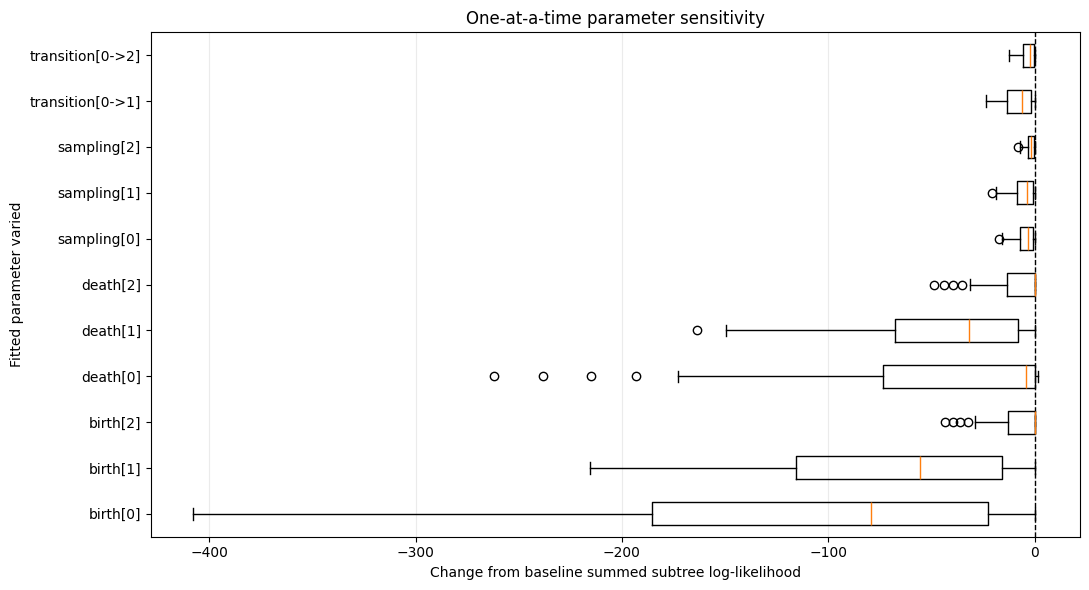

In [28]:
import matplotlib.pyplot as plt


def make_sensitivity_grid(original_value, lower_bound, upper_bound, points_per_side=20):
    original_value = float(original_value)
    if not lower_bound <= original_value <= upper_bound:
        raise ValueError("Sensitivity bounds must contain the original parameter")

    values = [torch.tensor([original_value], dtype=torch.float64)]
    if lower_bound < original_value:
        values.insert(
            0,
            torch.linspace(
                lower_bound,
                original_value,
                points_per_side + 1,
                dtype=torch.float64,
            )[:-1],
        )
    if upper_bound > original_value:
        values.append(
            torch.linspace(
                original_value,
                upper_bound,
                points_per_side + 1,
                dtype=torch.float64,
            )[1:],
        )
    return torch.cat(values)


parameter_sweeps = []
rate_margin = 1e-10
rate_delta = 2.0
probability_fraction = 0.2

for state_index, original_value in enumerate(birth_rates):
    lower_bound = max(
        1e-10,
        float(original_value) - rate_delta,
        float(death_rates[state_index]) + rate_margin,
    )
    upper_bound = min(20.0, float(original_value) + rate_delta)
    parameter_sweeps.append(
        (
            f"birth[{state_index}]",
            "birth",
            state_index,
            make_sensitivity_grid(float(original_value), lower_bound, upper_bound),
        )
    )

for state_index, original_value in enumerate(death_rates):
    lower_bound = max(1e-10, float(original_value) - rate_delta)
    upper_bound = min(
        10.0,
        float(original_value) + rate_delta,
        float(birth_rates[state_index]) - rate_margin,
    )
    parameter_sweeps.append(
        (
            f"death[{state_index}]",
            "death",
            state_index,
            make_sensitivity_grid(float(original_value), lower_bound, upper_bound),
        )
    )

for state_index, original_value in enumerate(sampling_probabilities):
    lower_bound = max(1e-8, float(original_value) * (1.0 - probability_fraction))
    upper_bound = min(1.0 - 1e-8, float(original_value) * (1.0 + probability_fraction))
    parameter_sweeps.append(
        (
            f"sampling[{state_index}]",
            "sampling",
            state_index,
            make_sensitivity_grid(float(original_value), lower_bound, upper_bound),
        )
    )

for target_state in (1, 2):
    original_value = float(transition_probabilities[0, target_state])
    other_outgoing_probability = sum(
        float(transition_probabilities[0, state])
        for state in range(1, num_states)
        if state != target_state
    )
    lower_bound = max(
        1e-8,
        original_value * (1.0 - probability_fraction),
    )
    upper_bound = min(
        original_value * (1.0 + probability_fraction),
        1.0 - other_outgoing_probability - 1e-8,
    )
    parameter_sweeps.append(
        (
            f"transition[0->{target_state}]",
            "transition",
            target_state,
            make_sensitivity_grid(original_value, lower_bound, upper_bound),
        )
    )

sensitivity_rows = []
for parameter_name, parameter_kind, parameter_index, parameter_values in parameter_sweeps:
    for candidate_value in parameter_values:
        trial_birth_rates = birth_rates.clone()
        trial_death_rates = death_rates.clone()
        trial_sampling_probabilities = sampling_probabilities.clone()
        trial_transition_probabilities = transition_probabilities.clone()

        if parameter_kind == "birth":
            trial_birth_rates[parameter_index] = candidate_value
        elif parameter_kind == "death":
            trial_death_rates[parameter_index] = candidate_value
        elif parameter_kind == "sampling":
            trial_sampling_probabilities[parameter_index] = candidate_value
        else:
            trial_transition_probabilities[0, parameter_index] = candidate_value
            trial_transition_probabilities[0, 0] = 1.0 - trial_transition_probabilities[0, 1:].sum()

        trial_u_result = calculate_Us(
            birth_rates=trial_birth_rates,
            death_rates=trial_death_rates,
            sampling_probabilities=trial_sampling_probabilities,
            transition_probabilities=trial_transition_probabilities,
            transition_times=torch.tensor(transition_times, dtype=torch.float64),
            root_times=root_times,
        )

        trial_total_loglikelihood = 0.0
        for (applicable_transition_times, datastructure) in sensitivity_inputs:
            loglikelihood_by_root_state = calculate_log_likelihood(
                datastructure=datastructure,
                birth_rates=trial_birth_rates,
                death_rates=trial_death_rates,
                transition_probabilities=trial_transition_probabilities,
                sampling_probabilities=trial_sampling_probabilities,
                Cs=trial_u_result.Cs[: len(applicable_transition_times) + 1],
                transition_times=applicable_transition_times,
            )
            trial_total_loglikelihood += float(loglikelihood_by_root_state[0, 0])

        sensitivity_rows.append(
            {
                "parameter": parameter_name,
                "parameter_value": float(candidate_value),
                "summed_log_likelihood": trial_total_loglikelihood,
            }
        )

parameter_sensitivity = pd.DataFrame(sensitivity_rows)
parameter_sensitivity["change_from_baseline"] = (
    parameter_sensitivity["summed_log_likelihood"] - total_subtree_loglikelihood
)
parameter_order = [sweep[0] for sweep in parameter_sweeps]
parameter_summary_rows = []
for parameter_name, _, _, parameter_values in parameter_sweeps:
    parameter_results = parameter_sensitivity[
        parameter_sensitivity["parameter"] == parameter_name
    ]
    best_row = parameter_results.loc[parameter_results["summed_log_likelihood"].idxmax()]
    parameter_summary_rows.append(
        {
            "parameter": parameter_name,
            "tested_min": float(parameter_values[0]),
            "tested_max": float(parameter_values[-1]),
            "likelihood_min": parameter_results["summed_log_likelihood"].min(),
            "likelihood_max": parameter_results["summed_log_likelihood"].max(),
            "likelihood_span": parameter_results["summed_log_likelihood"].max()
            - parameter_results["summed_log_likelihood"].min(),
            "best_tested_value": best_row["parameter_value"],
        }
    )
parameter_sensitivity_summary = pd.DataFrame(parameter_summary_rows)

if not torch.isclose(
    torch.tensor(total_subtree_loglikelihood, dtype=torch.float64),
    torch.tensor(baseline_loglikelihood, dtype=torch.float64),
    atol=1e-8,
    rtol=1e-10,
):
    raise AssertionError("The current baseline likelihoods do not match")

print(
    f"Ran one-at-a-time sensitivity for {len(parameter_sweeps)} fitted parameters; "
    f"transition times were held fixed."
)
print("Birth/death rates: additive +/-2, bounded to keep rates positive and birth > death.")
print("Sampling and free transition probabilities: relative +/-20%.")
print("Transition row diagonals are adjusted to preserve row sums.")
print(parameter_sensitivity_summary.to_string(index=False, float_format=lambda value: f"{value:.6f}"))

boxplot_values = [
    parameter_sensitivity.loc[
        parameter_sensitivity["parameter"] == parameter_name,
        "change_from_baseline",
    ].to_numpy()
    for parameter_name in parameter_order
]
figure_height = max(6, 0.38 * len(parameter_order))
fig, ax = plt.subplots(figsize=(11, figure_height))
ax.boxplot(boxplot_values, vert=False, tick_labels=parameter_order, showfliers=True)
ax.axvline(0.0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Change from baseline summed subtree log-likelihood")
ax.set_ylabel("Fitted parameter varied")
ax.set_title("One-at-a-time parameter sensitivity")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()
